100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.6MB/s]


Running Experiment: SGD_MiniBatch_ReLU
Final Accuracy: 83.81% | Time: 79.03s

Running Experiment: Momentum_MiniBatch_ReLU
Final Accuracy: 86.84% | Time: 78.53s

Running Experiment: RMSProp_MiniBatch_ReLU
Final Accuracy: 87.73% | Time: 79.96s

Running Experiment: Adam_MiniBatch_ReLU
Final Accuracy: 87.08% | Time: 80.32s

Running Experiment: Adam_Stochastic_ReLU
Final Accuracy: 83.97% | Time: 1154.12s

Running Experiment: Adam_FullBatch_ReLU
Final Accuracy: 60.83% | Time: 77.43s

Running Experiment: Adam_MiniBatch_MultiLayer
Final Accuracy: 87.61% | Time: 91.52s

Running Experiment: Adam_MiniBatch_Sigmoid
Final Accuracy: 86.21% | Time: 81.93s



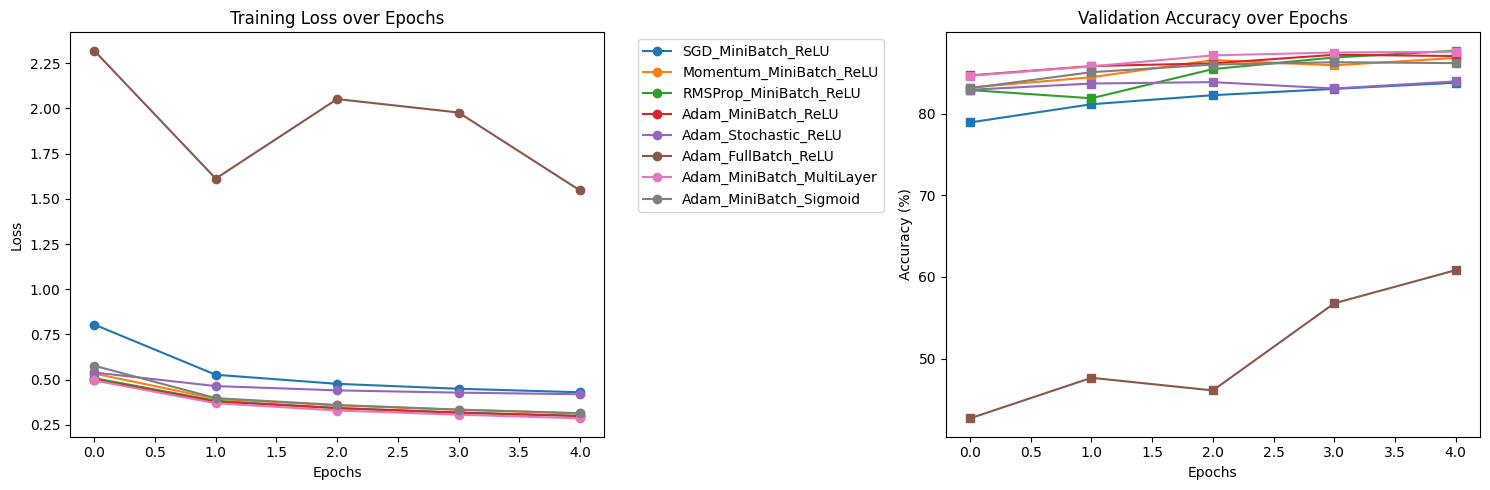

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time
import numpy as np

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

def get_data_loaders(batch_size):
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

class SingleLayerNN(nn.Module):
    """Feed-forward NN with 1 Hidden Layer"""
    def __init__(self, input_size=784, hidden_size=128, num_classes=10, activation=nn.ReLU()):
        super(SingleLayerNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.activation = activation
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.activation(self.fc1(x))
        x = self.fc2(x)
        return x

class MultiLayerNN(nn.Module):
    """Feed-forward NN with 2 Hidden Layers"""
    def __init__(self, input_size=784, hidden_nodes=[256, 128], num_classes=10, activation=nn.ReLU()):
        super(MultiLayerNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_nodes[0])
        self.activation1 = activation
        self.fc2 = nn.Linear(hidden_nodes[0], hidden_nodes[1])
        self.activation2 = activation
        self.fc3 = nn.Linear(hidden_nodes[1], num_classes)

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.activation1(self.fc1(x))
        x = self.activation2(self.fc2(x))
        x = self.fc3(x)
        return x

def train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=5):
    model.to(device)
    history = {'train_loss': [], 'test_accuracy': [], 'time': 0}

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        history['train_loss'].append(epoch_loss)

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        epoch_acc = 100 * correct / total
        history['test_accuracy'].append(epoch_acc)

    history['time'] = time.time() - start_time
    return history

def run_experiments():
    criterion = nn.CrossEntropyLoss()
    results = {}

    configs = {
        "SGD_MiniBatch_ReLU": {"model": SingleLayerNN(), "batch": 64, "opt": "SGD", "lr": 0.01},
        "Momentum_MiniBatch_ReLU": {"model": SingleLayerNN(), "batch": 64, "opt": "Momentum", "lr": 0.01},
        "RMSProp_MiniBatch_ReLU": {"model": SingleLayerNN(), "batch": 64, "opt": "RMSProp", "lr": 0.001},
        "Adam_MiniBatch_ReLU": {"model": SingleLayerNN(), "batch": 64, "opt": "Adam", "lr": 0.001},
        "Adam_Stochastic_ReLU": {"model": SingleLayerNN(), "batch": 1, "opt": "Adam", "lr": 0.001},
        "Adam_FullBatch_ReLU": {"model": SingleLayerNN(), "batch": 60000, "opt": "Adam", "lr": 0.01},
        "Adam_MiniBatch_MultiLayer": {"model": MultiLayerNN(), "batch": 64, "opt": "Adam", "lr": 0.001},
        "Adam_MiniBatch_Sigmoid": {"model": SingleLayerNN(activation=nn.Sigmoid()), "batch": 64, "opt": "Adam", "lr": 0.001}
    }

    for name, config in configs.items():
        print(f"Running Experiment: {name}")
        train_loader, test_loader = get_data_loaders(config["batch"])
        model = config["model"]

        if config["opt"] == "SGD":
            optimizer = optim.SGD(model.parameters(), lr=config["lr"])
        elif config["opt"] == "Momentum":
            optimizer = optim.SGD(model.parameters(), lr=config["lr"], momentum=0.9)
        elif config["opt"] == "RMSProp":
            optimizer = optim.RMSprop(model.parameters(), lr=config["lr"])
        elif config["opt"] == "Adam":
            optimizer = optim.Adam(model.parameters(), lr=config["lr"])

        hist = train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, epochs=5)
        results[name] = hist
        print(f"Final Accuracy: {hist['test_accuracy'][-1]:.2f}% | Time: {hist['time']:.2f}s\n")

    return results

def plot_results(results):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    for name, hist in results.items():
        ax1.plot(hist['train_loss'], label=name, marker='o')
        ax2.plot(hist['test_accuracy'], label=name, marker='s')

    ax1.set_title('Training Loss over Epochs')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    ax2.set_title('Validation Accuracy over Epochs')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')

    plt.tight_layout()
    plt.show()

results = run_experiments()
plot_results(results)